# Ranking Spike Sequences by Fitness and Evaluating Cumulative Tip Scores

In this notebook, we explore multiple ranking methods to prioritize spike sequences based on their fitness estimates. These methods include:

- PyR0 fitness scores  
- EVEscape model scores  
- CoVFit model scores

We then evaluate the performance of each ranking by analyzing how well the top-ranked sequences capture future tips cumulatively over various time slices.

This approach helps identify ranking strategies that best forecast viral evolutionary trends and guide variant surveillance.


In [1]:
# --- VaccineScout configuration -------------------------------------------
# Makes scripts/ importable regardless of where the kernel was started, then
# loads every path and parameter from config.yaml at the repository root.
import sys
from pathlib import Path

_SCRIPTS_DIR = Path.cwd() if (Path.cwd() / "config_loader.py").is_file() else Path.cwd() / "scripts"
_SCRIPTS_DIR = _SCRIPTS_DIR.resolve()
if str(_SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(_SCRIPTS_DIR))

from config_loader import load_config

cfg = load_config()
print(f"Loaded config from {cfg.config_path}")

import pandas as pd
import matplotlib.pyplot as plt
import pickle

# --- Custom imports ---
from Helpers import *   # Contains utility functions for data processing and plotting

# Configure matplotlib for consistent plots
plt.style.use("seaborn-v0_8-whitegrid")


Loaded config from /home/pgangwar@AD.UCSD.EDU/FutureCoV/config.yaml


In [2]:
def load_data(file_path):
    """
    Loads a two-column Parquet file and converts it back into a Python dictionary.
    """
    # 1. Read the Parquet file into a DataFrame
    df = pd.read_parquet(file_path)
    
    # 2. Zip the 'key' and 'value' columns together and convert to a dict
    return dict(zip(df['key'], df['value']))

In [3]:
# --- Load data files ---
ROOT_PATH = cfg.data_root_str
DATA_PATH = cfg.file("final_df")
final_df = pd.read_parquet(DATA_PATH)
id_to_seq = load_data(cfg.file("sequence_dict"))

refSeq = getReference(cfg.file("ref_spike_genome"))

ver = cfg.pyro_version

pyro_df = read_pickle(cfg.pyro_spike_pickle(ver))

# Backbone chosen via `analysis.eve_backbone` in config.yaml
# (e.g. EVEscore_Wuhan_A, EVEscore_Omicron_BA.4, EVEscore_Omicron_XBB)
eve_df = pd.read_csv(cfg.eve_scores())

In [4]:
start_date = pd.Timestamp(cfg.start_date)
end_date = pd.Timestamp(cfg.end_date)

filtered_df = final_df[
    final_df["Date"].between(start_date, end_date)
]

sample_mask = ~final_df["Sample_ID"].str.startswith("node_", na=False)
filtered_df = filtered_df[sample_mask]

/tmp/ipykernel_3317740/196734536.py:9: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  filtered_df = filtered_df[sample_mask]


Create Disjoint time interval slices

In [5]:
# --- Define cutoff date ---
cutoff_date = cfg.cutoff_date

# --- Split dataframe into circulating and future segments ---
# Window geometry comes from the `analysis:` block in config.yaml.
current_df, future_df = split_circulating_and_future(
    final_df,
    cutoff_date_str=cutoff_date,
    **cfg.split_kwargs()
)

# --- Define windows for slicing future data ---
disjoint_windows = cfg.disjoint_windows

# --- Perform slicing ---
future_slices = slice_by_disjoint_windows(future_df, disjoint_windows)

# --- Summary output ---
print(f"Total future slices stored: {len(future_slices)}")

Total future slices stored: 2


In [6]:
# --- Compute tip counts for current circulating sequences ---
current_seq_df = (
    current_df.groupby('Sequence_ID')
    .size()
    .reset_index(name='Tip_Count')
    .sort_values(by='Tip_Count', ascending=False)
    .reset_index(drop=True)
)

min_tip_count = cfg.min_tip_count
current_seq_df = (
    current_seq_df[current_seq_df['Tip_Count'] >= min_tip_count]
    .reset_index(drop=True)
)

# --- Compute tip counts for each future window ---
future_seq_dfs = {
    k: (
        v.groupby('Sequence_ID')
        .size()
        .reset_index(name='Tip_Count')
        .sort_values(by='Tip_Count', ascending=False)
        .reset_index(drop=True)
    )
    for k, v in future_slices.items()
}

# --- Summary output ---
print(f"Computed current sequence DataFrame with {len(current_seq_df)} unique sequences")
print(f"Computed future sequence DataFrames for {len(future_seq_dfs)} windows")

Computed current sequence DataFrame with 2392 unique sequences
Computed future sequence DataFrames for 2 windows


# CoVFit Fitness Score Ranking

We will compute the CoVFit ranking using the precomputed per-sequence average fitness scores.

In [7]:
import subprocess
from pathlib import Path

# --- Write current sequences to FASTA for CoVFit ---
# Resolve CoVFit_CLI relative to this notebook (scripts/rank_analysis.ipynb)
COVFIT_DIR = cfg.covfit_dir
fasta_path = cfg.file("rank_current_fasta")

missing_ids = []
n_written = 0
with open(fasta_path, "w") as fasta_file:
    for seq_id in current_seq_df["Sequence_ID"]:
        seq = id_to_seq.get(seq_id)
        if seq is None:
            missing_ids.append(seq_id)
            continue
        fasta_file.write(f">{seq_id}\n{seq}\n")
        n_written += 1

print(f"Wrote {n_written:,} sequences to {fasta_path}")
if missing_ids:
    print(f"Warning: {len(missing_ids):,} Sequence_IDs missing from id_to_seq")

# --- Run CoVFit CLI ---
covfit_outdir = cfg.covfit_outdir(cutoff_date, "current")
covfit_cmd = cfg.covfit_command(fasta_path, covfit_outdir)
print("Running:", " ".join(covfit_cmd))

result = subprocess.run(
    covfit_cmd,
    cwd=str(COVFIT_DIR),
    capture_output=True,
    text=True,
)
print(result.stdout)
if result.stderr:
    print(result.stderr)
if result.returncode != 0:
    raise RuntimeError(f"covfit_cli failed with exit code {result.returncode}")

covfit_output = cfg.covfit_predictions(covfit_outdir)
print(f"CoVFit predictions written to {covfit_output}")


Wrote 2,392 sequences to /home/pgangwar@AD.UCSD.EDU/FutureCoV/data/current_seq_df.fasta
Running: ./covfit_cli -i /home/pgangwar@AD.UCSD.EDU/FutureCoV/data/current_seq_df.fasta -o /home/pgangwar@AD.UCSD.EDU/FutureCoV/data/2022-06-01/current_covfit -g -b 16 -f 3
Initializing model. Please wait...
Tokenizing sequences for model input
Running CoVFit
Predictions completed
Writing output to /home/pgangwar@AD.UCSD.EDU/FutureCoV/data/2022-06-01/current_covfit/CoVFit_Predictions_fold_3.tsv
Done

Detected kernel version 5.4.0, which is below the recommended minimum of 5.5.0; this can cause the process to hang. It is recommended to upgrade the kernel to the minimum version or higher.

100%|██████████| 75/75 [03:20<00:00,  2.68s/it]

CoVFit predictions written to /home/pgangwar@AD.UCSD.EDU/FutureCoV/data/2022-06-01/current_covfit/CoVFit_Predictions_fold_3.tsv


In [8]:
# --- Load CoVFit fitness scores ---
covfit_outdir = cfg.covfit_outdir(cutoff_date, "current")
covfit_output = cfg.covfit_predictions(covfit_outdir)

covfit_score_df = pd.read_csv(covfit_output, sep="\t")
covfit_score_df = covfit_score_df.rename(columns={"seq_name": "Sequence_ID"})

current_seq_df = current_seq_df.merge(
    covfit_score_df[["Sequence_ID", "fitness_mean"]],
    on="Sequence_ID",
    how="left",
)

print(f"Loaded {len(covfit_score_df):,} CoVFit score entries")
print(f"Merged fitness scores into current sequence DataFrame with {len(current_seq_df):,} sequences")


Loaded 2,392 CoVFit score entries
Merged fitness scores into current sequence DataFrame with 2,392 sequences


# PyR0 and EVEscape Ranking

Rank sequences using:
- **PyR₀ score**: product of R/Rₐ values across all spike mutations.  
- **EVEscape score**: sum of EVEsape scores across all soike mutations using Wuhan_A scoring.  


In [9]:
# --- Build mutation-to-score dictionaries ---
mutation_score_dict_pyro = (
    pyro_df.set_index("mutation")["R / R_A"].to_dict()
)

# EVEscape scores every mutation against its own backbone, so the lookup key is
# that backbone's residue: wt + pos + mut.
mutation_score_dict_eve = (
    eve_df.assign(key=eve_df["wt"] + eve_df["pos"].astype(str) + eve_df["mut"])
    .set_index("key")["EVEscape"]
    .to_dict()
)

# --- Reconstruct the EVEscape backbone and express it against Wuhan ---
# 'wt' is the backbone's residue at each site, so the sites where it disagrees
# with ref_spike_genome are exactly the backbone's mutations. Empty for Wuhan.
eve_backbone = eve_df.drop_duplicates("pos").set_index("pos")["wt"]
eve_ref_mutations = {
    pos: allele for pos, allele in eve_backbone.items() if refSeq[pos - 1] != allele
}

# --- Summary output ---
print(f"Loaded {len(mutation_score_dict_pyro)} PyR₀ mutation scores")
print(f"Loaded {len(mutation_score_dict_eve)} EVEscape mutation scores")
print(
    f"EVEscape backbone differs from Wuhan at {len(eve_ref_mutations)} site(s): "
    + (", ".join(f"{refSeq[p - 1]}{p}{a}" for p, a in sorted(eve_ref_mutations.items()))
       or "none (Wuhan)")
)

Loaded 2474 PyR₀ mutation scores
Loaded 24187 EVEscape mutation scores
EVEscape backbone differs from Wuhan at 27 site(s): T19I, G142D, V213G, G339D, S371F, S373P, S375F, T376A, D405N, K417N, N440K, L452R, S477N, T478K, E484A, F486V, Q498R, N501Y, Y505H, D614G, H655Y, N679K, P681H, N764K, D796Y, Q954H, N969K


In [10]:
# --- Add mutation information to current sequences ---
current_seq_df = add_mutations_column(current_seq_df, id_to_seq, refSeq)

# --- Compute PyR₀ fitness scores ---
current_seq_df = add_fitness_scores_pyro(current_seq_df, mutation_score_dict_pyro)


# --- Re-express each sequence's mutations against the EVEscape backbone ---
def to_eve_ref_mutations(mutations):
    """Convert Wuhan-relative mutations to backbone-relative ones.

    At every site touched by the sequence or the backbone, compare the residue
    each one carries and emit a mutation only where they differ:
      - same mutation                 -> dropped, the sequence already matches
      - different mutation            -> backbone residue becomes the wild type
      - backbone only contains site   -> reversal back to the Wuhan mutation
      - sequence only contains site   -> kept unchanged (backbone is Wuhan there)
    With EVEscore_Wuhan_A the backbone is empty, so this returns 'Mutations'.
    """
    seq_alleles = {}
    for m in mutations:
        _wt, pos, alt = get_mutation_pattern(m)
        if not pos:
            continue
        seq_alleles[pos] = alt

    rebased = []
    for pos in sorted(set(seq_alleles) | set(eve_ref_mutations)):
        wuhan = refSeq[pos - 1]
        ref_allele = eve_ref_mutations.get(pos, wuhan)
        seq_allele = seq_alleles.get(pos, wuhan)
        if seq_allele == ref_allele:
            continue
        rebased.append(f"S:{ref_allele}{pos}{seq_allele}")
    return tuple(rebased)


current_seq_df["eve_ref_mutations"] = [
    to_eve_ref_mutations(muts) for muts in current_seq_df["Mutations"]
]

# --- Compute EVEscape fitness scores ---
current_seq_df = add_fitness_scores_eve(
    current_seq_df, mutation_score_dict_eve, mutations_col="eve_ref_mutations"
)

# --- Summary output ---
print(f"Computed mutations and fitness scores for {len(current_seq_df)} sequences")

Computed mutations and fitness scores for 2392 sequences


In [11]:
# --- Build oracle ranking of current sequences for each future window ---
oracle_rankings = build_oracle_current_rankings(
    current_seq_df,
    future_seq_dfs,
    random_state=0,
)

print(f"Built oracle rankings for {len(oracle_rankings)} time windows")

Built oracle rankings for 2 time windows


In [12]:
# --- Compute cumulative tip percentages for all ranking methods ---
rank_results = compute_cumulative_tip_percentages_fast(
    current_seq_df,
    future_seq_dfs,
    oracle_rankings=oracle_rankings,
    max_rank=None
)

# --- Summary output ---
print(f"Computed cumulative tip percentages for {len(rank_results)} future time windows")

Computed cumulative tip percentages for 2 future time windows


In [13]:
# --- Compute normalized AUC for each ranking method ---
auc_scores = compute_auc_for_rank_results(rank_results)
df = pd.DataFrame(auc_scores)
df.index.name = 'Model'

print(cutoff_date, df)

2022-06-01                6M_1      6M_2
Model                        
pyro       0.667831  0.074440
eve        0.039201  0.003530
covfit     0.676905  0.075203
tip_count  0.701766  0.070173
oracle     0.731770  0.077377


# Plotting Results in a six-month period

The following plots visualize the performance of different ranking methods in capturing future tips.  
Each main panel shows the cumulative fraction of future tips captured by the top-ranked sequences over a given time interval.  
Inset panels display the corresponding normalized AUC scores for each method, with a reference line indicating the achievable ceiling.

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import numpy as np

sns.set_style("whitegrid")
sns.set_context("talk")

def plot_1x2_cumulative_auto(rank_results, auc_scores, cutoff_date):
    slice_keys = list(rank_results.keys())[:4]

    legend_map = {
        "pyro": "PyR0 Fitness Score",
        "eve": "EVEscape Fitness Score",
        "covfit": "CoVFit Fitness Score",
        "tip_count": "Prevalence Score",
        "oracle": "Theoretical Best Ranking",
    }
    panel_head = {
        '6M_1': '0 - 6 months',
        '6M_2': '6 - 12 months'
    }

    base_palette = sns.color_palette("colorblind", n_colors=4)
    color_map = {
        "pyro": base_palette[0],
        "eve": base_palette[1],
        "covfit": base_palette[2],
        "tip_count": base_palette[3],
        "oracle": "black",
    }

    fig, axes = plt.subplots(1, 2, figsize=(30, 12), sharex=True, sharey=True)
    axes = axes.flatten()
    plt.subplots_adjust(wspace=0.51, top=0.865)  # Add this line to create space between plots
    fig.suptitle(f'Fraction of Future Sequences Captured by Ranking Models: {cutoff_date}', fontsize=30, y = 0.95)

    legend_handles = []
    legend_labels = []

    for i, key in enumerate(slice_keys):
        df = rank_results[key]
        ax = axes[i]

        tip_cols = [col for col in df.columns if col.startswith('%_tips_')]
        methods = [col.replace('%_tips_', '') for col in tip_cols]
        bar_methods = [m for m in methods if m != "oracle"]

        # Main lineplots
        for method in methods:
            label_name = legend_map.get(method, method)
            line_kwargs = {
                "data": df,
                "x": "Rank",
                "y": f"%_tips_{method}",
                "ax": ax,
                "linewidth": 2.5,
                "color": color_map[method],
                "legend": False,
            }
            if method == "oracle":
                line_kwargs["linestyle"] = "--"
            sns.lineplot(**line_kwargs)
            if label_name not in legend_labels:
                legend_handles.append(ax.lines[-1])
                legend_labels.append(label_name)

        # X-axis ticks
        max_rank = int(df['Rank'].max())
        # Anchor on 10 and 500, then step in thousands. The old ladder set
        # tick_base to 10/100/1000 by magnitude, so a year whose max_rank
        # landed under 2000 drew 21 evenly spaced ticks while one above drew
        # 5 -- the same linear axis reading as linear in one figure and as
        # logarithmic in another. This keeps every cutoff looking alike.
        tick_vals = [v for v in (10, 500) if v <= max_rank]
        tick_vals += list(range(1000, max_rank + 1, 1000))
        if len(tick_vals) < 3:  # max_rank < 1000; the anchors alone are too sparse
            step = max(1, round(max_rank / 4 / 10) * 10)
            tick_vals = list(range(step, max_rank + 1, step))
        tick_vals = sorted(set(tick_vals))
        tick_labels = [f'{x//1000}K' if x >= 1000 else str(x) for x in tick_vals]
        ax.set_xticks(tick_vals)
        ax.set_xticklabels(tick_labels, rotation=45, fontsize=20)
        ax.tick_params(axis='y', labelsize=20)

        ax.set_title(f'Fraction of Future Sequences Captured in {panel_head[key]}', fontsize=28)
        ax.set_xlabel('Top Rank', fontsize=26)
        ax.set_ylabel('Normalized Tip Score', fontsize=26)

        # --- Inset AUC bar plot, bottom-right, no x-ticks ---
        if auc_scores is not None and key in auc_scores:
            inset_ax = inset_axes(ax, width="25%", height="25%", loc='lower right', borderpad=1)
            best_auc = auc_scores[key]["oracle"]
            auc_values = [auc_scores[key].get(m, 0) for m in bar_methods]
            inset_ax.bar(range(len(bar_methods)), auc_values, color=[color_map[m] for m in bar_methods])
            inset_ax.set_title("Normalized AUC", fontsize=20)
            inset_ax.set_xticks([])  # remove x-ticks
            inset_ax.set_xlabel("")
            inset_ax.tick_params(axis='y', labelsize=20)
            inset_ax.set_ylim(0, 1.05)
            inset_ax.set_yticks([0, 0.25, 0.50, 0.75, 1.00])
            inset_ax.set_yticklabels(['0', '0.25', '0.50', '0.75', '1.00'])
            inset_ax.grid(False)
            inset_ax.axhline(y=best_auc, color='black', linestyle='--', linewidth=2)

    # Shared legend outside
    fig.legend(
        handles=legend_handles,
        labels=legend_labels,
        loc='center',
        bbox_to_anchor=(0.51, 0.5),
        fontsize=20,
        title="Ranking Methods",
        title_fontsize=22
    )

    plt.savefig(cfg.cutoff_dir(cutoff_date) / 'overlap.svg', format='svg', bbox_inches='tight', dpi=300)
    plt.show()

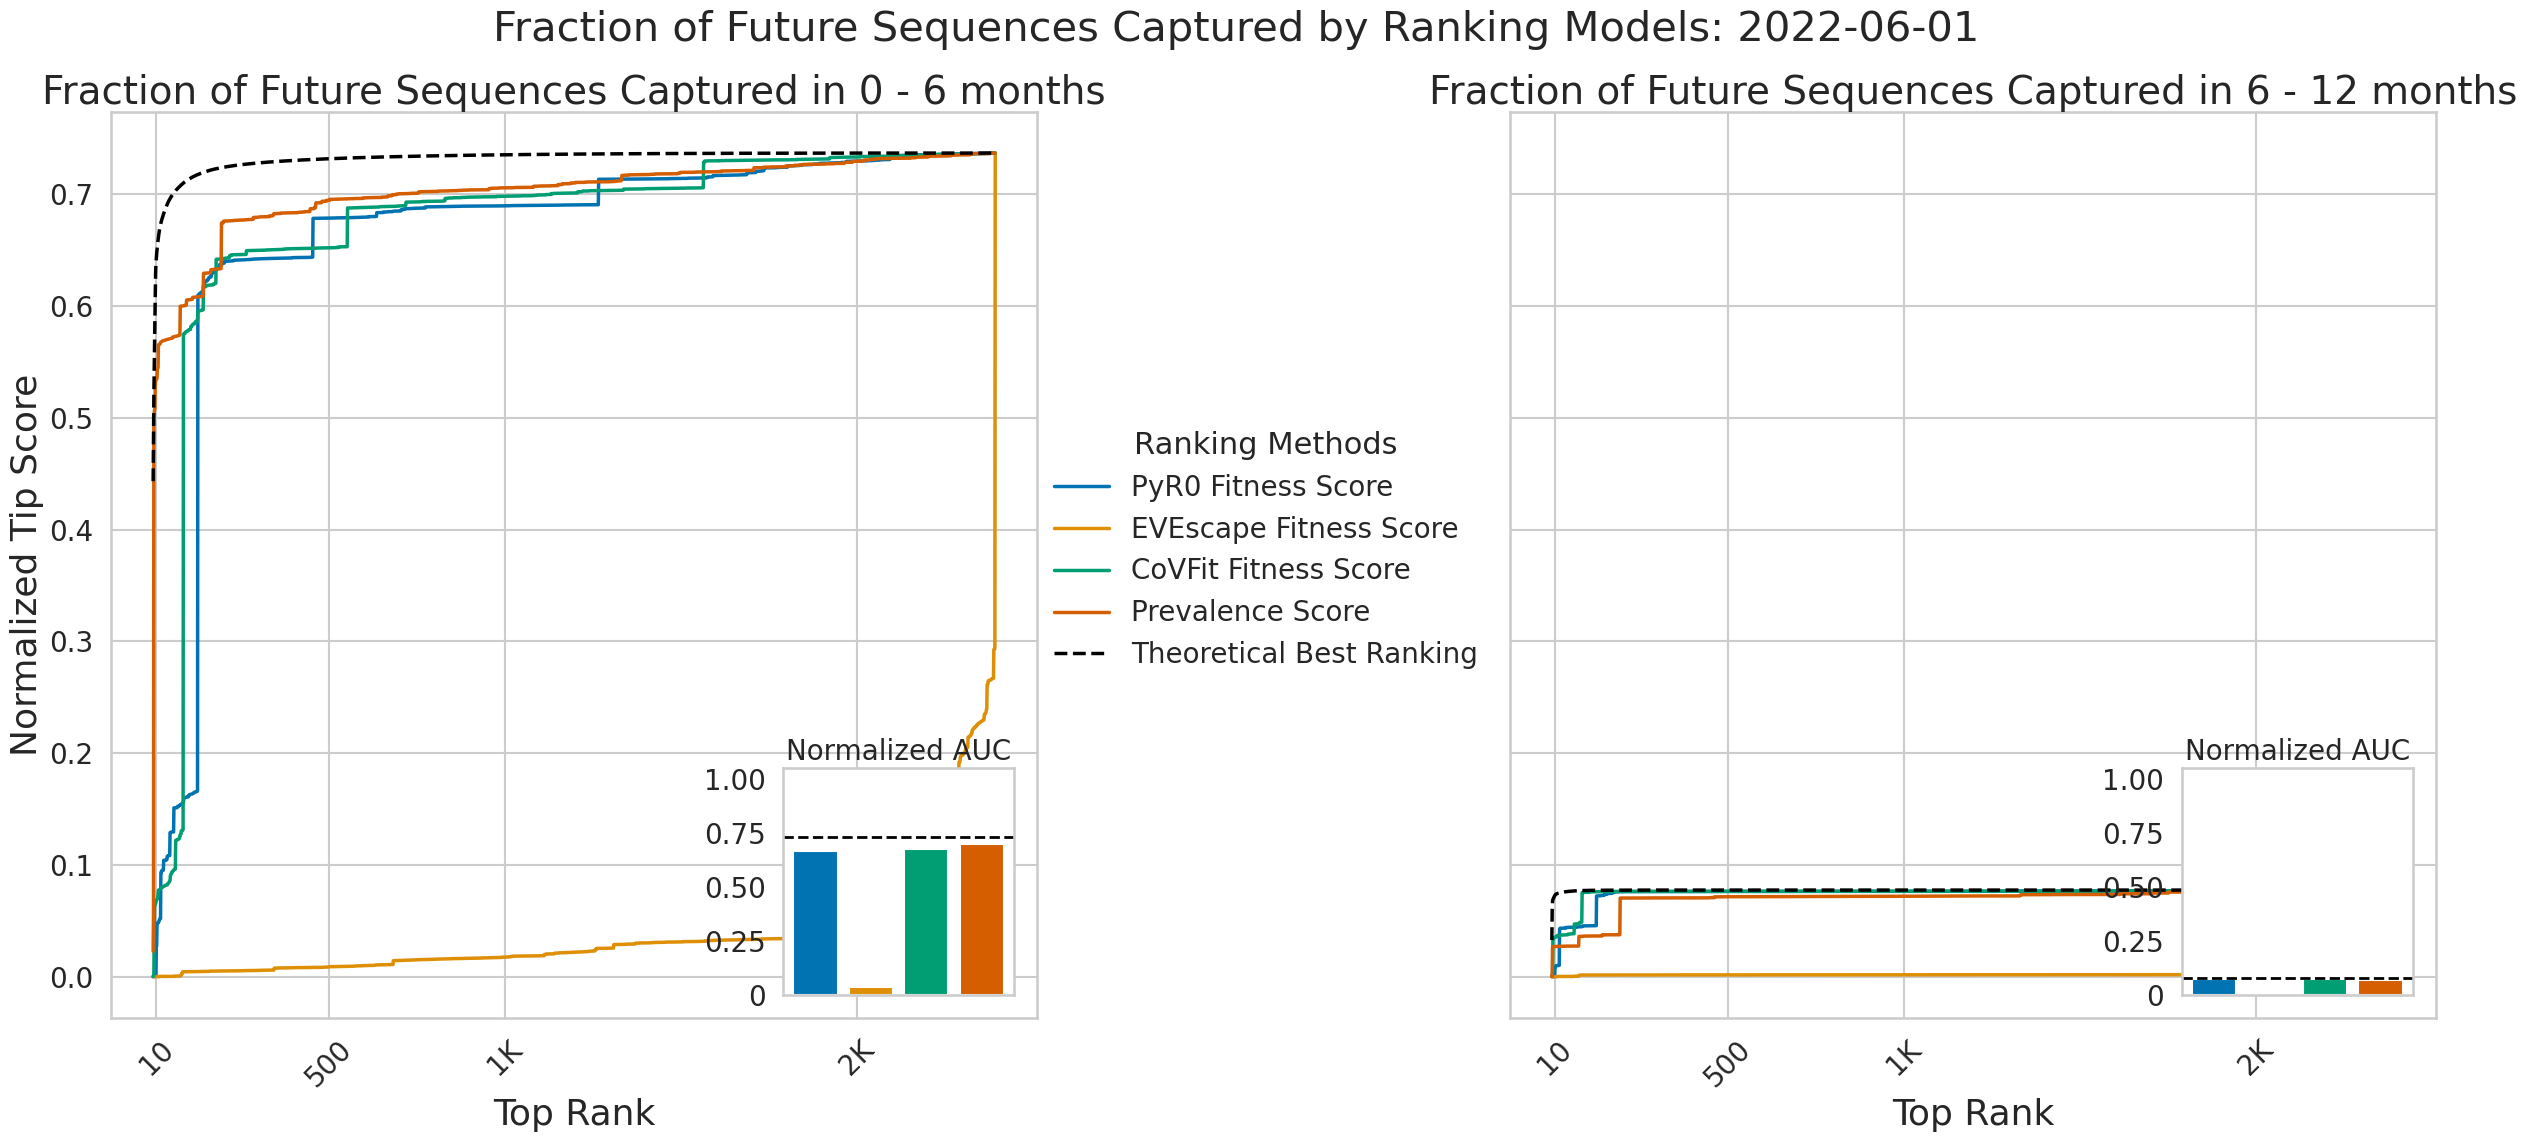

In [15]:
plot_1x2_cumulative_auto(rank_results=rank_results,
                         auc_scores=auc_scores,
                         cutoff_date=cutoff_date)